# Token-based features: indicators, bag-of-words and character n-grams

This notebook is the clean record of our experiments with token-based features. It walks through what we tried, in the order we tried it, and why each decision was made. The working notebook with the raw runs is `bow_bti_project.ipynb`.

**How to run it:** every number is loaded from `shared/results/`, so the notebook runs in a few minutes and retrains nothing. Set `RUN_MISSING = True` in the setup cell to train a system that has no saved result yet (slow for MLP and ResMLP).

**Contents**
1. Setup
2. Why the folds are grouped by prompt
3. Tokenisers: which ones, and why not the tutorial's
4. Features: indicators, bag-of-words, character n-grams
5. Models and protocol
6. Iteration: the MLP at chance level, and the fix
7. Results and comparisons
8. Scaling: the decisive factor for count features
9. Errors of the best token-based system

## Decisions at a glance

| Decision | Choice | Main reason | Section |
|---|---|---|---|
| Folds | Grouped by `prompt_id`; 50 folds (10 × 5) for logistic regression, the first 5 for MLP and ResMLP | Kaggle's test prompts are unseen; neural runs take 1–2.5 h on 50 folds | 2, 5 |
| Tokenisers | Our own `ours-bpe` at 2k, 4k, 8k, plus LUSR's pretrained BPE; not the tutorial BPE | The tutorial BPE turns typography into `[UNK]`; typography is the strongest cue in our data | 3 |
| Input scaling | **No standardisation of count features** | Standardising inflates rare tokens; without it every token feature set gains 3–13 points (decided for all), and the inner split never chooses scaling | 8 |
| Vocabulary size | No clear winner; larger is slightly better without scaling | Unscaled: 2k < 4k < 8k < LUSR's tokeniser, every step undecided. The 2k advantage under the shared protocol was a scaling artefact | 7, 8 |
| Representations | Token indicators and bag-of-words (tutorial), character 2-4-grams (extra) | The rubric asks for the first two; character n-grams see typography without any tokeniser | 4 |
| Indicators or counts | Counts (bag-of-words) | Without scaling, counts are 2–3 points ahead for every tokeniser (P = 0.82–0.95, just short of a verdict) | 8 |
| Models | Shared `logreg`, `mlp` (one hidden layer, as in the tutorial) and `resmlp` | Same models and grids as for the LUSR and Qwen embeddings, so results compare directly | 5 |
| Architecture of choice | Logistic regression | Without scaling, the MLP is level with it and the ResMLP is 3–6 points worse (decided for 2 of 6 feature sets); logistic regression is the cheapest and can be read | 7, 8 |
| MLP input scaling bug | Columns that never vary in a training fold are left unscaled | Without this, the MLP fell to chance level on large vocabularies | 6 |
| Best token-based system | Bag-of-words on LUSR's tokeniser, unscaled logistic regression | Highest mean (32.8%); not decidedly below LUSR embeddings + logistic regression (35.8%) | 8, 9 |


## 1 · Setup

In [1]:
import sys

sys.path.insert(0, "..")  # this notebook lives in root/part1, so `shared` and `part1` are importable

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from part1.clslib import Encoder
from shared import analysis as A, eval_harness as H
from shared.data import load_data
from shared.tokenization import get_tokenizer, preprocess, tokenize, tokenizer_stats

DATA = load_data()
d = DATA.train
y, groups = DATA.y, DATA.groups
FOLDS = H.load_folds(d["id"].tolist())  # 10 repeats x 5 folds = 50
FOLDS_5 = H.load_folds(d["id"].tolist(), repeats=1)  # first repeat only, for the slow neural models
print(d.shape, len(DATA.classes), "classes |", len(FOLDS), "folds")

RESULTS = {}  # name -> run_cv result
RECOMPUTE = False  # True: retrain even when a saved result exists
RUN_MISSING = False  # True: train systems that have no saved result yet
NEURAL_SUFFIX = "-sdfix"  # MLP/ResMLP results computed after the scaling fix of section 6


def cv(name, X, model, folds=None, **kw):
    """Load the saved result for `name`, or train it (on `folds`) when RUN_MISSING or RECOMPUTE is set."""
    if H.MODELS[model].neural and not name.endswith(NEURAL_SUFFIX):
        name += NEURAL_SUFFIX
    saved = H.load_results(name.replace("/", "__") + ".json")
    if saved and not RECOMPUTE:
        RESULTS[name], status = saved[name], "loaded"
    elif RUN_MISSING or RECOMPUTE:
        folds = folds or (FOLDS_5 if H.MODELS[model].neural else FOLDS)
        RESULTS[name] = H.run_cv(X, y, groups, folds, model, name=name, verbose=False, **kw)
        H.save_result(RESULTS[name])
        status = "trained"
    else:
        print(f"{name:34s} not saved yet")
        return None
    ba = H.fold_scores(RESULTS[name])
    print(f"{name:34s} bal.acc {ba.mean():.4f} ± {ba.std():.4f}  ({len(ba)} folds, {status})")
    return RESULTS[name]

(2159, 4) 18 classes | 50 folds


**Reproducibility:** the split, folds and seeds are fixed in `shared/` (`data.py`, `folds.json`, `eval_harness.py`, seed 42 + repeat). The notebook needs no seeding of its own: each fold seeds itself inside its worker process.

## 2 · Why the folds are grouped by prompt

All 18 LLMs answer every prompt, and Kaggle's test prompts never appear in `train.csv`. If answers to one prompt sat on both sides of a split, validation would test on familiar topics. The check below shows how strong the topic is: every text is compared with every other text by TF-IDF cosine similarity.

In [2]:
tfidf = TfidfVectorizer(sublinear_tf=True, min_df=2).fit_transform(d["text"])
S = (tfidf @ tfidf.T).toarray()
P, M = d["prompt_id"].to_numpy(), d["model"].to_numpy()
same_p, same_m, off = P[:, None] == P[None, :], M[:, None] == M[None, :], ~np.eye(len(d), dtype=bool)
np.fill_diagonal(S, -1)
nn = S.argmax(1)
display(pd.Series({
    "same prompt, different LLM": S[same_p & ~same_m].mean(),
    "same LLM, different prompt": S[same_m & ~same_p & off].mean(),
    "different prompt and LLM": S[~same_p & ~same_m].mean(),
    "nearest neighbour answers the same prompt": np.mean(P[nn] == P),
    "nearest neighbour comes from the same LLM": np.mean(M[nn] == M),
}, name="word TF-IDF").round(3).to_frame())

,word TF-IDF
"same prompt, different LLM",0.246
"same LLM, different prompt",0.039
different prompt and LLM,0.036
nearest neighbour answers the same prompt,1.000
nearest neighbour comes from the same LLM,0.000


**Finding:** texts are far more similar to other answers to the same prompt than to the same LLM's answers on other prompts, and a text's nearest neighbour almost always answers the same prompt. The topic dominates the surface of the text, so random folds would let a model use topic matches that do not exist for unseen prompts. Grouped folds remove that shortcut.

## 3 · Tokenisers

Bag-of-words and indicators work with any tokeniser, because they only count token ids. We compared four:

| Tokeniser | Registry name | Vocabulary | Trained on |
|---|---|---|---|
| Ours, 2k | `ours-bpe-2k` | 2,000 | Our training split (`part1/tok.py`) |
| Ours, 4k | `ours-bpe-4k` | 4,000 | Our training split |
| Ours, 8k | `ours-bpe-8k` | 8,000 | Our training split |
| LUSR | `roberta-bpe` | ~50,000 | Pretrained (RoBERTa byte-level BPE) |

**Why not the tutorial tokeniser:** the tutorial's BPE was trained on AG News with 1,000 tokens. It turns newlines, curly quotes, em dashes and accented letters into `[UNK]` (58% of our passages contain at least one, see `neural_project.ipynb`, step 4). Typography is the strongest cue in our data (EDA, step 1 of `project.ipynb`), so a tokeniser that deletes it is the wrong starting point.

**Why 2k, 4k and 8k:** we shortlisted 2k and 4k on intrinsic metrics (tokens per word, unseen-word coverage, cue preservation; `project.ipynb`, step 2) and added 8k as a comparison closest to the pretrained tokenisers. Intrinsic metrics only measure how text is split, not how well an author is identified, so the final choice is made downstream in sections 7 and 8.

**Why we first treated the LUSR tokeniser only as a comparison.** The name suggests it carries LUSR's knowledge of writing style, but it does not:

1. **The style knowledge is in LUSR's weights, not its vocabulary.** `roberta-bpe` is the general byte-level BPE that LUSR inherited from RoBERTa, trained on web text, not on authorship. Counting its tokens uses none of what LUSR learned; that only happens when the text goes through the trained model (LUSR embeddings + logistic regression, `lusr/logreg`, 35.8%).
2. **Its vocabulary is far too large for our data.** 50,265 entries, of which 16,176 occur in our 2,159 training texts, and about half of those in fewer than 5 texts (table in section 4). With about 1,700 training texts per fold, most columns are too rare to learn a weight from.
3. **Many of its tokens are prompt-specific.** In 96% of validation texts at least one token never occurs in the training fold (section 6), which is what broke the MLP.
4. **Its pre-tokenisation hides some typography.** Byte-level BPE attaches spaces and some punctuation to the following word, and treats the straight apostrophe (`'s` merged into one token) differently from the curly one (`project.ipynb`, step 2). Our BPE isolates punctuation, so each cue stays its own token.
5. **It is expensive.** The MLPs densify their input, so 16,176 columns make every neural run several times slower than with 2k.

We still ran it, because it answers one useful question: *is a large pretrained tokeniser better for count features than a small one trained on our data?* Under the shared protocol (standardised input, section 7) the answer is no. Without standardisation (section 8) it becomes the best tokeniser, though not decidedly: points 2 and 3 turned out to be a problem of scaling rare tokens, not of the vocabulary itself.

In [3]:
TOKENIZERS = {"ours2k": "ours-bpe-2k", "ours4k": "ours-bpe-4k", "ours8k": "ours-bpe-8k", "lusr": "roberta-bpe"}
texts = d["text"].tolist()
display(tokenizer_stats(texts, names=list(TOKENIZERS.values())).round(4))

,vocab,fertility,mean_tokens,max_tokens,truncated@512,unk_rate,docs_with_unk,probe_roundtrip
tokenizer,,,,,,,,
ours-bpe-2k,2000,1.9662,225.8370,585,0.0107,0.0,0.0,He said “no” — it’s 5 [UNK]m[UNK] done
ours-bpe-4k,4000,1.6405,188.4303,506,0.0000,0.0,0.0,He said “no” — it’s 5 [UNK]m[UNK] done
ours-bpe-8k,8000,1.3881,159.4423,420,0.0000,0.0,0.0,He said “no” — it’s 5 [UNK]m[UNK] done
roberta-bpe,50265,1.2937,148.5943,385,0.0000,0.0,0.0,He said “no” — it’s 5 µm… done


## 4 · Features

`TokenIndicator` and `BagOfWords` follow the `Encoder` classes of the tutorial. Two changes: tokenisers are loaded by name from `shared/tokenization.py`, so all experiments use the same ones, and `__len__` reads `self` (the tutorial's version reads a global `tokenizer`). The tutorial leaves `BagOfWords` as an exercise, so that class is ours.

- **Token indicators:** 1 if the token occurs in the text, otherwise 0.
- **Bag-of-words:** how often each token occurs.
- **Character 2-4-grams (extra):** counts of runs of 2 to 4 characters, case kept, the 20,000 most frequent. No tokeniser is involved, so typography such as `’` or ` — ` is counted directly. The 20,000 cap keeps the dense MLP input manageable; it was not tuned.

`encode_all` drops tokens that never occur in the training split, because those columns are always zero.

**Fitted on the whole training split, not per fold:** `ours-bpe`, the kept columns and the character n-gram vocabulary all see the validation prompts of every fold, without their labels. `run_cv` takes one fixed matrix, so per-fold fitting would need changes to the shared code. This makes the scores slightly optimistic, and it matters for section 6.

In [4]:
def vocab_size(tokenizer_name):
    tokenizer = get_tokenizer(tokenizer_name)
    return tokenizer.get_vocab_size() if hasattr(tokenizer, "get_vocab_size") else len(tokenizer)


class TokenIndicator(Encoder):
    def __init__(self, tokenizer_name):
        self.tokenizer_name = tokenizer_name
        self.size = vocab_size(tokenizer_name)

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return self.size

    def __call__(self, x: str) -> np.ndarray:
        """Represent x as a D-dimensional vector of real numbers"""
        unique_token_ids = list(set(tokenize([x], self.tokenizer_name)[0]))
        vector = np.zeros(len(self))
        vector[unique_token_ids] = 1
        return vector


class BagOfWords(Encoder):
    def __init__(self, tokenizer_name):
        self.tokenizer_name = tokenizer_name
        self.size = vocab_size(tokenizer_name)

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return self.size

    def __call__(self, x: str) -> np.ndarray:
        """Represent x as a D-dimensional vector of real numbers"""
        token_ids = tokenize([x], self.tokenizer_name)[0]
        return np.bincount(token_ids, minlength=len(self)).astype(float)


def encode_all(texts, encoder):
    """Stack encoder(text) for every text, dropping tokens that never occur in these texts."""
    X = sp.vstack([sp.csr_matrix(encoder(text)) for text in texts], format="csr")
    return X[:, np.unique(X.indices)]


def char_ngrams(texts, ngram_range=(2, 4), max_features=20_000):
    """Counts of the most frequent character n-grams; case and typography are authorship cues, so both stay."""
    vectorizer = CountVectorizer(analyzer="char", ngram_range=ngram_range, lowercase=False, max_features=max_features)
    return vectorizer.fit_transform([preprocess(text) for text in texts]).astype(float).tocsr()

In [5]:
FEATURES = {}
for short_name, tokenizer_name in TOKENIZERS.items():
    FEATURES[f"indicator-{short_name}"] = encode_all(texts, TokenIndicator(tokenizer_name))
    FEATURES[f"bow-{short_name}"] = encode_all(texts, BagOfWords(tokenizer_name))
FEATURES["char-2-4grams"] = char_ngrams(texts)

display(pd.DataFrame(
    {"columns": X.shape[1], "non-zeros per text": round(X.nnz / X.shape[0]),
     "share of columns in < 5 texts": round(float(np.mean(X.getnnz(axis=0) < 5)), 3)}
    for X in FEATURES.values()
).set_index(pd.Index(list(FEATURES), name="features")))

,columns,non-zeros per text,share of columns in < 5 texts
features,,,
indicator-ours2k,1988,160,0.021
bow-ours2k,1988,160,0.021
indicator-ours4k,3916,140,0.040
bow-ours4k,3916,140,0.040
indicator-ours8k,7573,119,0.089
bow-ours8k,7573,119,0.089
indicator-lusr,16176,110,0.526
bow-lusr,16176,110,0.526
char-2-4grams,20000,1319,0.000


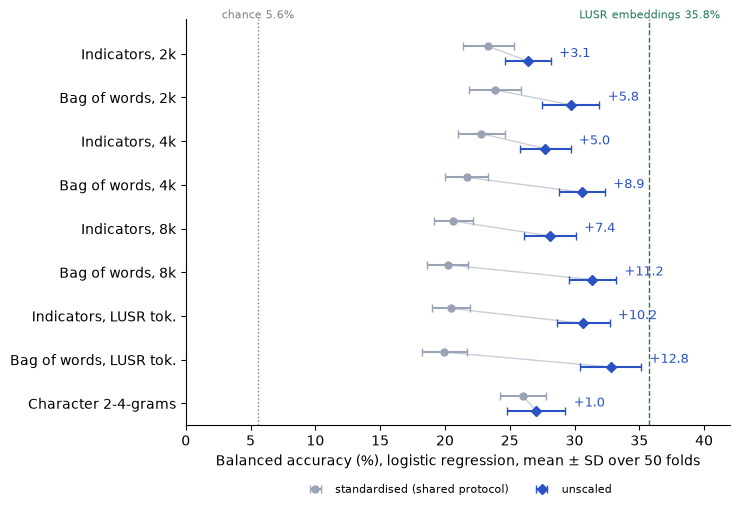

In [6]:
import matplotlib.pyplot as plt

R = H.load_results()
rows = [  # label, feature set
    ("Indicators, 2k", "indicator-ours2k"), ("Bag of words, 2k", "bow-ours2k"),
    ("Indicators, 4k", "indicator-ours4k"), ("Bag of words, 4k", "bow-ours4k"),
    ("Indicators, 8k", "indicator-ours8k"), ("Bag of words, 8k", "bow-ours8k"),
    ("Indicators, LUSR tok.", "indicator-lusr"), ("Bag of words, LUSR tok.", "bow-lusr"),
    ("Character 2-4-grams", "char-2-4grams"),
]
stat = lambda n: (100 * H.fold_scores(R[n]).mean(), 100 * H.fold_scores(R[n]).std())
off = 0.17  # vertical offset between the two dots of a row

fig, ax = plt.subplots(figsize=(7.5, 5.2))
for i, (label, rep) in enumerate(rows):
    (m1, s1), (m2, s2) = stat(f"{rep}/logreg"), stat(f"{rep}/logreg_unscaled")
    ax.plot([m1, m2], [i - off, i + off], color="#c9ced8", lw=1, zorder=0)
    ax.errorbar(m1, i - off, xerr=s1, fmt="o", color="#9aa3b5", capsize=3, ms=5,
                label="standardised (shared protocol)" if i == 0 else None)
    ax.errorbar(m2, i + off, xerr=s2, fmt="D", color="#2a52c4", capsize=3, ms=5,
                label="unscaled" if i == 0 else None)
    ax.annotate(f"{m2 - m1:+.1f}", (max(m1 + s1, m2 + s2), i), textcoords="offset points", xytext=(6, 0),
                va="center", fontsize=9, color="#2a52c4")

for x, txt, col, ls in [(100 / 18, "chance 5.6%", "grey", ":"), (stat("lusr/logreg")[0], "LUSR embeddings 35.8%", "#1d7a4e", "--")]:
    ax.axvline(x, ls=ls, color=col, lw=1)
    ax.text(x, -0.75, txt, fontsize=8, color=col, ha="center", va="bottom")

ax.set_yticks(range(len(rows)), [r[0] for r in rows])
ax.set_ylim(len(rows) - 0.5, -0.8)
ax.set_xlim(0, 42)
ax.set_xlabel("Balanced accuracy (%), logistic regression, mean ± SD over 50 folds")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False, fontsize=8)
plt.tight_layout()
plt.show()


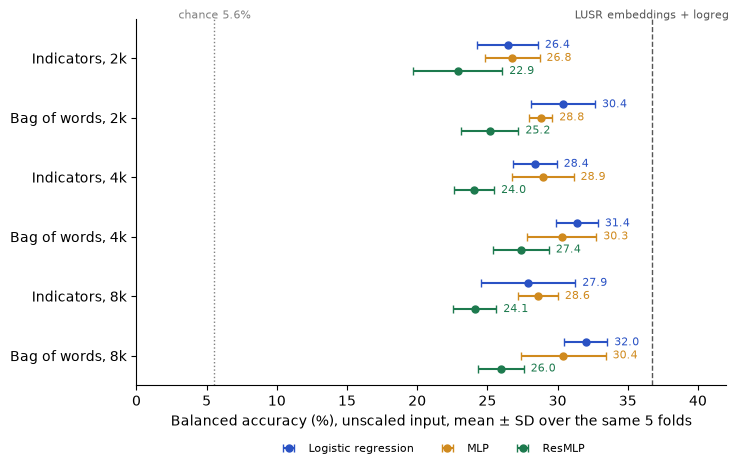

In [7]:
import matplotlib.pyplot as plt

R = H.load_results()
reps = [("Indicators, 2k", "indicator-ours2k"), ("Bag of words, 2k", "bow-ours2k"),
        ("Indicators, 4k", "indicator-ours4k"), ("Bag of words, 4k", "bow-ours4k"),
        ("Indicators, 8k", "indicator-ours8k"), ("Bag of words, 8k", "bow-ours8k")]
models = [  # label, result suffix, colour
    ("Logistic regression", "logreg_unscaled", "#2a52c4"),
    ("MLP", "mlp_unscaled", "#d08a1e"),
    ("ResMLP", "resmlp_unscaled", "#1d7a4e"),
]
offsets = [-0.22, 0.0, 0.22]


def stat(name):
    s = 100 * H.fold_scores(H.subset_repeats(R[name], 1))  # same first 5 folds for every model
    return s.mean(), s.std()


fig, ax = plt.subplots(figsize=(7.5, 4.8))
for i, (_, rep) in enumerate(reps):
    for (label, m, col), off in zip(models, offsets):
        name = f"{rep}/{m}"
        if name not in R:
            continue
        mean, sd = stat(name)
        ax.errorbar(mean, i + off, xerr=sd, fmt="o", color=col, capsize=3, ms=5, label=label if i == 0 else None)
        ax.annotate(f"{mean:.1f}", (mean + sd, i + off), textcoords="offset points", xytext=(5, 0),
                    va="center", fontsize=8, color=col)

lusr5 = 100 * H.fold_scores(H.subset_repeats(R["lusr/logreg"], 1)).mean()
for x, txt, col, ls in [(100 / 18, "chance 5.6%", "grey", ":"), (lusr5, "LUSR embeddings + logreg", "#555", "--")]:
    ax.axvline(x, ls=ls, color=col, lw=1)
    ax.text(x, -0.62, txt, fontsize=8, color=col, ha="center", va="bottom")

ax.set_yticks(range(len(reps)), [r[0] for r in reps])
ax.set_ylim(len(reps) - 0.5, -0.65)
ax.set_xlim(0, 42)
ax.set_xlabel("Balanced accuracy (%), unscaled input, mean ± SD over the same 5 folds")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3, frameon=False, fontsize=8)
plt.tight_layout()
plt.show()


## 5 · Models and protocol

All models come from `shared/eval_harness.py`, so the count features use exactly the models, grids, folds and statistical test of the embedding experiments (`neural_project.ipynb`).

| | Logistic regression (`logreg`) | MLP (`mlp`) | Residual MLP (`resmlp`) |
|---|---|---|---|
| Role in the rubric | Log-linear model | Single-hidden-layer MLP | Modification of the MLP |
| Architecture | Multinomial, StandardScaler | Linear, ReLU, dropout, linear | Projection, 2–3 pre-LayerNorm residual blocks, linear head |
| Tuned per fold (nested) | C ∈ {1e-4 … 10} | width, dropout, learning rate, weight decay (16 settings) | blocks, width, dropout, learning rate (16 settings) |
| Folds | 50 | first 5 | first 5 |

**The MLP compared with the tutorial's:** the architecture is the same kind (one hidden layer, ReLU, dropout, AdamW, batch 64). The differences are the shared protocol: standardised inputs, light input dropout, tuned settings instead of the tutorial's fixed AG News settings, and early stopping on an *inner* split. The tutorial picks its best epoch on the fold it reports, which makes its score optimistic; nested tuning avoids that.

**Nested tuning:** inside each outer training fold, 20% of its prompts form an inner validation set. The best setting is chosen there and refitted on the whole outer training fold, so the reported fold plays no part in any choice.

**Why only 5 folds for MLP and ResMLP:** the measured 50-fold run times below. `shared/README.md` allows the first repeat for costly models, and `H.compare` pairs 5-fold and 50-fold systems on their 5 common folds. The price is wider posteriors for neural comparisons.

In [8]:
runtime = pd.DataFrame(
    {"model": r["model"], "folds": len(r["folds"]), "minutes": r["seconds"] / 60}
    for r in H.load_results().values()
    if r["name"].split("/")[0] in FEATURES
).groupby(["model", "folds"])["minutes"].describe()[["count", "min", "max"]].round(1)
display(runtime)

count   min    max
model              folds                    
logreg             50       9.0   0.5    9.7
logreg_scale_tuned 50       2.0   2.4    4.8
logreg_unscaled    50       9.0   0.7   73.1
mlp                5        6.0   4.2   19.4
                   50       4.0  41.5  150.5
mlp_unscaled       5        6.0   4.1   17.9
resmlp             5        6.0   4.3   10.6
                   50       2.0  44.3   49.5
resmlp_unscaled    5        6.0   4.8   11.5

## 6 · Iteration: the MLP at chance level, and the fix

**What happened:** the first MLP runs on the LUSR tokeniser scored 5.7%, which is chance for 18 classes (1/18 = 5.6%). Logistic regression on the same features scored about 20%, so the information was there and the MLP was broken.

**Cause:** the shared MLP standardises each column with the training fold's mean and standard deviation, plus `1e-6`. A token that never occurs in the training fold but does occur in validation has a standard deviation of 0. One occurrence then becomes (1 − 0) / 0.000001 = **1,000,000**, multiplied by a weight that never trained. That swamps every other input. Such tokens exist because the tokeniser and the kept columns come from the whole training split (section 4). Logistic regression is unaffected: scikit-learn's `StandardScaler` divides constant columns by 1.

**Fix (in `shared/eval_harness.py`, `TorchClassifier._prep`):** columns that never vary in the training fold are left unscaled, as in scikit-learn. Results computed after the fix carry the suffix `-sdfix`.

The table shows how often this happens per feature set (first 10 folds): larger vocabularies have more prompt-specific tokens, and because folds are grouped, one such token appears in all 18 answers to its prompt.

In [9]:
def unseen_tokens(X, folds):
    """Per fold: columns absent from the training part but present in validation, and the share of validation texts hit."""
    cols, hit = [], []
    for _, _, tr, te in folds:
        unseen = np.flatnonzero((X[tr].getnnz(axis=0) == 0) & (X[te].getnnz(axis=0) > 0))
        cols.append(len(unseen))
        hit.append((X[te][:, unseen].getnnz(axis=1) > 0).mean())
    return {"unseen columns per fold": np.mean(cols), "validation texts affected": np.mean(hit)}


display(pd.DataFrame({name: unseen_tokens(X, FOLDS[:10]) for name, X in FEATURES.items() if name.startswith("indicator") or name.startswith("char")}).T.round(3))

,unseen columns per fold,validation texts affected
indicator-ours2k,7.1,0.031
indicator-ours4k,27.8,0.258
indicator-ours8k,137.8,0.802
indicator-lusr,1240.9,0.959
char-2-4grams,93.5,0.534


The comparison below pairs each pre-fix run with its fixed run on their common folds (the first 5), so both columns use the same folds. Pre-fix runs are kept for this table only and are never used in section 7.

In [10]:
REPS = ["indicator-ours2k", "bow-ours2k", "indicator-ours4k", "bow-ours4k", "indicator-ours8k", "bow-ours8k",
        "indicator-lusr", "bow-lusr", "char-2-4grams"]
SAVED = H.load_results()
rows = []
for rep in REPS:
    for model in ["mlp", "resmlp"]:
        old, new = SAVED.get(f"{rep}/{model}"), SAVED.get(f"{rep}/{model}{NEURAL_SUFFIX}")
        if old is None or new is None:
            continue
        c = H.compare(old, new)
        old_same = H.subset_repeats(old, new["runs"])  # pre-fix scores on the fixed run's folds only
        rows.append({"system": f"{rep}/{model}", "pre-fix": H.fold_scores(old_same).mean(), "fixed": H.fold_scores(new).mean(),
                     "paired folds": c["n_folds"], "mean fixed − pre-fix": c["mean_diff"], "P(fixed better)": c["p_b_better"]})
display(pd.DataFrame(rows).set_index("system").round(4) if rows else "No pre-fix/fixed pairs saved yet.")

,pre-fix,fixed,paired folds,mean fixed − pre-fix,P(fixed better)
system,,,,,
indicator-ours2k/mlp,0.2339,0.2422,5,0.0083,0.3885
indicator-ours2k/resmlp,0.2088,0.2288,5,0.0200,0.8063
bow-ours2k/mlp,0.2445,0.2537,5,0.0092,0.4614
bow-ours2k/resmlp,0.2422,0.2445,5,0.0023,0.0512
indicator-ours4k/mlp,0.1857,0.2417,5,0.0560,0.9970
bow-ours4k/mlp,0.1811,0.2214,5,0.0403,0.9971


**Finding:** the fix matters exactly where the table above predicts. On 2k, where 3% of validation texts contain an unseen token, the fixed and pre-fix runs differ by 0.2–2 points and no difference is decided. On 4k, where 26% are affected, the MLP gains 4–5.6 points (P(fixed better) = 0.997 for both feature types). Pre-fix 8k, LUSR-tokeniser and character n-gram MLPs were stopped or never saved, so they have no row; from the table above they would have been hit hardest. All MLP and ResMLP numbers in section 7 come from the fixed code only.

## 7 · Results and comparisons (shared protocol: standardised input)

Every system: balanced accuracy in % (number of folds). Logistic regression uses 50 folds, MLP and ResMLP the first 5. The column *logreg, first 5 folds* is the same logistic regression on the 5 folds the neural models use; compare MLP and ResMLP with that column, not with the 50-fold one. A dash means the run has not been saved yet.

In [11]:
for rep in REPS:
    for model in ["logreg", "mlp", "resmlp"]:
        cv(f"{rep}/{model}", FEATURES[rep], model)

RESULTS_ALL = {**RESULTS, **H.load_results("lusr__logreg.json")}  # LUSR embeddings + logreg: our best system without fine-tuning (neural_project.ipynb)


def cell(name):
    r = RESULTS_ALL.get(name)
    return "–" if r is None else f"{100 * H.fold_scores(r).mean():.1f} ({len(r['folds'])})"


def cell5(name):
    """Same as cell(), on the first repeat only (the 5 folds the MLP and ResMLP use), for a like-for-like comparison."""
    r = RESULTS_ALL.get(name)
    return "–" if r is None else f"{100 * H.fold_scores(H.subset_repeats(r, 1)).mean():.1f} (5)"


SUMMARY = pd.DataFrame(
    {m: [cell(f"{rep}/{m}" + (NEURAL_SUFFIX if H.MODELS[m].neural else "")) for rep in REPS] for m in ["logreg", "mlp", "resmlp"]},
    index=pd.Index(REPS, name="features"),
)
SUMMARY.insert(1, "logreg, first 5 folds", [cell5(f"{rep}/logreg") for rep in REPS])
display(SUMMARY)
print("For reference, LUSR embeddings + logreg:", cell("lusr/logreg"))

indicator-ours2k/logreg            bal.acc 0.2335 ± 0.0197  (50 folds, loaded)
indicator-ours2k/mlp-sdfix         bal.acc 0.2422 ± 0.0208  (5 folds, loaded)
indicator-ours2k/resmlp-sdfix      bal.acc 0.2288 ± 0.0157  (5 folds, loaded)
bow-ours2k/logreg                  bal.acc 0.2388 ± 0.0199  (50 folds, loaded)
bow-ours2k/mlp-sdfix               bal.acc 0.2537 ± 0.0104  (5 folds, loaded)
bow-ours2k/resmlp-sdfix            bal.acc 0.2445 ± 0.0380  (5 folds, loaded)
indicator-ours4k/logreg            bal.acc 0.2279 ± 0.0181  (50 folds, loaded)
indicator-ours4k/mlp-sdfix         bal.acc 0.2417 ± 0.0155  (5 folds, loaded)
indicator-ours4k/resmlp-sdfix      bal.acc 0.2177 ± 0.0138  (5 folds, loaded)
bow-ours4k/logreg                  bal.acc 0.2169 ± 0.0165  (50 folds, loaded)
bow-ours4k/mlp-sdfix               bal.acc 0.2214 ± 0.0144  (5 folds, loaded)
bow-ours4k/resmlp-sdfix            bal.acc 0.2149 ± 0.0159  (5 folds, loaded)
indicator-ours8k/logreg            bal.acc 0.2065 ± 0.0150  

,logreg,"logreg, first 5 folds",mlp,resmlp
features,,,,
indicator-ours2k,23.4 (50),24.6 (5),24.2 (5),22.9 (5)
bow-ours2k,23.9 (50),24.8 (5),25.4 (5),24.5 (5)
indicator-ours4k,22.8 (50),23.0 (5),24.2 (5),21.8 (5)
bow-ours4k,21.7 (50),22.0 (5),22.1 (5),21.5 (5)
indicator-ours8k,20.7 (50),21.2 (5),18.4 (5),19.3 (5)
bow-ours8k,20.2 (50),20.6 (5),18.7 (5),19.8 (5)
indicator-lusr,20.5 (50),20.7 (5),–,–
bow-lusr,20.0 (50),20.2 (5),–,–
char-2-4grams,26.0 (50),26.0 (5),–,–


For reference, LUSR embeddings + logreg: 35.8 (50)


The comparisons below use the Bayesian correlated t-test with ROPE = 1 percentage point (justified in `neural_project.ipynb`, step 6). Each row asks one question; the verdict is given when a probability exceeds 0.95.

In [12]:
def have(*names):
    return all(n in RESULTS_ALL for n in names)


QUESTIONS = []
for f in ["bow", "indicator"]:
    for other in ["ours4k", "ours8k", "lusr"]:
        QUESTIONS.append(("tokeniser", f"{f}-ours2k/logreg", f"{f}-{other}/logreg"))
for tok in ["ours2k", "ours4k", "ours8k", "lusr"]:
    QUESTIONS.append(("indicator vs counts", f"indicator-{tok}/logreg", f"bow-{tok}/logreg"))
for rep in REPS:
    QUESTIONS.append(("architecture", f"{rep}/logreg", f"{rep}/mlp{NEURAL_SUFFIX}"))
    QUESTIONS.append(("architecture", f"{rep}/mlp{NEURAL_SUFFIX}", f"{rep}/resmlp{NEURAL_SUFFIX}"))
QUESTIONS += [("third representation", "bow-ours2k/logreg", "char-2-4grams/logreg"),
              ("vs LUSR embeddings", "char-2-4grams/logreg", "lusr/logreg")]
QUESTIONS = [q for q in QUESTIONS if have(q[1], q[2])]

CMP_TABLE, CMPS = A.comparison_table(RESULTS_ALL, pairs=[(a, b) for _, a, b in QUESTIONS])
CMP_TABLE.insert(0, "question", [q for q, _, _ in QUESTIONS])
CMP_TABLE["verdict"] = np.select(
    [CMP_TABLE["P(B>A)"] > 0.95, CMP_TABLE["P(A>B)"] > 0.95, CMP_TABLE["P(ROPE)"] > 0.95],
    ["B better", "A better", "practically equivalent"], "undecided")
display(CMP_TABLE)

,question,A,B,folds,mean B−A,P(A>B),P(ROPE),P(B>A),verdict
0,tokeniser,bow-ours2k/logreg,bow-ours4k/logreg,50,-0.0219,0.8487,0.1476,0.0037,undecided
1,tokeniser,bow-ours2k/logreg,bow-ours8k/logreg,50,-0.0367,0.9961,0.0039,0.0000,A better
2,tokeniser,bow-ours2k/logreg,bow-lusr/logreg,50,-0.0392,0.9843,0.0155,0.0002,A better
3,tokeniser,indicator-ours2k/logreg,indicator-ours4k/logreg,50,-0.0056,0.3424,0.5803,0.0773,undecided
4,tokeniser,indicator-ours2k/logreg,indicator-ours8k/logreg,50,-0.0270,0.9170,0.0812,0.0018,undecided
5,tokeniser,indicator-ours2k/logreg,indicator-lusr/logreg,50,-0.0288,0.9389,0.0600,0.0011,undecided
6,indicator vs counts,indicator-ours2k/logreg,bow-ours2k/logreg,50,0.0053,0.0610,0.6246,0.3144,undecided
7,indicator vs counts,indicator-ours4k/logreg,bow-ours4k/logreg,50,-0.0110,0.5455,0.4436,0.0108,undecided
8,indicator vs counts,indicator-ours8k/logreg,bow-ours8k/logreg,50,-0.0045,0.2527,0.7039,0.0434,undecided
9,indicator vs counts,indicator-lusr/logreg,bow-lusr/logreg,50,-0.0051,0.2151,0.7766,0.0083,undecided


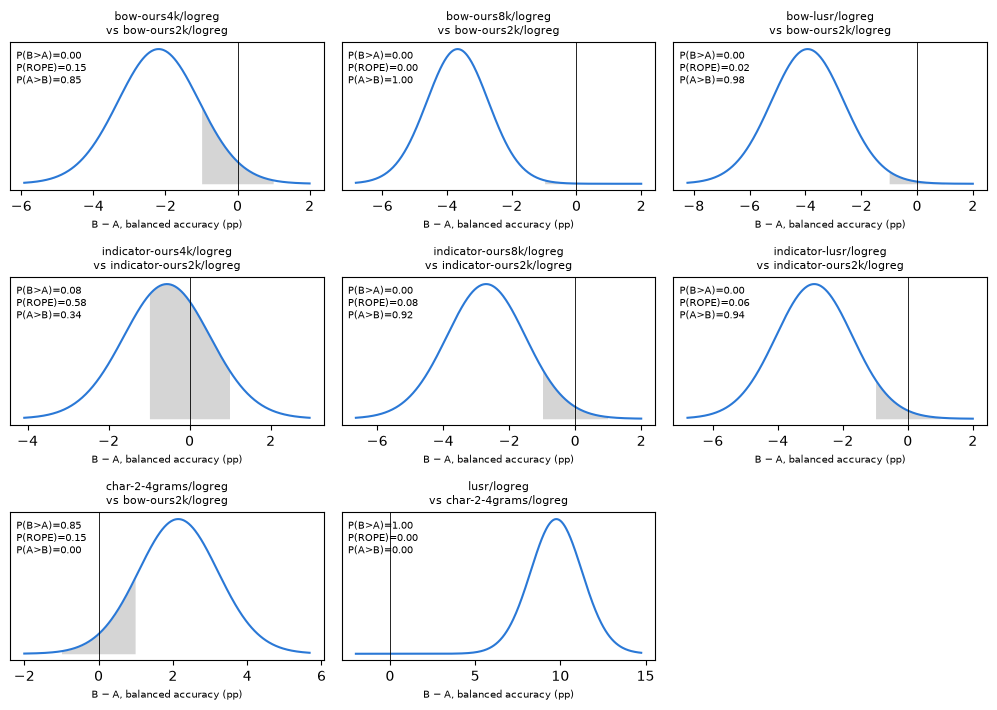

In [13]:
A.plot_posteriors([c for c, (q, _, _) in zip(CMPS, QUESTIONS) if q in ("tokeniser", "third representation", "vs LUSR embeddings")], ncols=3)
plt.show()

**Findings (logistic regression, 50 folds, always scaled as in the shared protocol):**
- **Vocabulary size: smaller is better under this protocol.** Accuracy falls from 2k to 4k to 8k for both feature types. For bag-of-words, 2k is clearly better than 8k and than LUSR's tokeniser (P > 0.98); against 4k it is likely better but not decided (P = 0.85). For indicators, 2k is ahead of 8k and LUSR with P ≈ 0.92–0.94, short of our 0.95 threshold. This matches our intrinsic finding (`project.ipynb`, step 2) that 2k generalises best to new prompts, and section 6 shows the mechanism: larger vocabularies add prompt-specific tokens that never occur in the training fold. **Section 8 shows that this ranking is an artefact of standardisation and reverses without it.**
- **A large pretrained tokeniser does not help count features:** LUSR's tokeniser is no better than our 8k BPE (see section 3 for why).
- **Indicators vs counts: no clear difference** under this protocol for any tokeniser (all undecided, mostly inside or near the ROPE). Most of the signal is *which* tokens occur, not how often.
- **Character n-grams (26.0%)** are ahead of bag-of-words on 2k (23.9%) with P = 0.85, which is suggestive but not decided.
- **Every token-based system here stays well below LUSR embeddings + logreg** (35.8%; character n-grams are 9.8 points behind, P = 1.00). Section 8 shows that most of this gap comes from scaling, not from the features.

**Findings (MLP and ResMLP, 5 folds, fixed code):**
- **No architecture is clearly better.** All 12 architecture comparisons are undecided. On the same 5 folds, the MLP is within about 1 point of logistic regression on 2k and 4k (best: bag-of-words on 2k, 25.4% vs 24.8%), which is inside or near the ROPE. With only 5 folds, a difference would have to be large and consistent to be decided.
- **Larger vocabularies hurt the neural models more.** On 8k, both MLPs fall below logistic regression (MLP 18.4–18.7% vs 20.6–21.2%; P(logreg better) = 0.75–0.88). An 8k input has about 7,600 columns for about 1,400 inner training texts, and 80% of validation texts contain a token never seen in training (section 6): more parameters to fit from the same few texts.
- **The same tokeniser ranking holds:** 2k ≥ 4k > 8k for every architecture, so the choice of 2k does not depend on the model.
- **ResMLP never beats the MLP clearly.** It is slightly behind on 2k and 4k and slightly ahead on 8k, all undecided. The residual blocks were designed for dense embeddings; on sparse counts they add parameters without adding a useful inductive bias.
- **This matches the embedding experiments:** on LUSR embeddings, `neural_project.ipynb` also found the three architectures practically equivalent. With about 1,700 training texts per fold, extra capacity does not pay off, whatever the features.
- **Logistic regression** is never clearly worse, runs on 50 folds in minutes instead of hours, and its weights can be read directly. Section 8 repeats these comparisons without scaling, where the MLP catches up with logistic regression and the ResMLP falls behind.
- **Not run:** MLP and ResMLP on the LUSR tokeniser (16,176 columns) and on character n-grams (20,000 columns). Both are densified in the MLP, so one fold took way too long, and given the 8k trend we did not expect them to beat logistic regression.

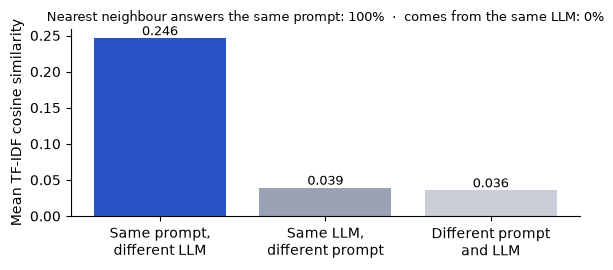

In [14]:
import matplotlib.pyplot as plt

P, M = d["prompt_id"].to_numpy(), d["model"].to_numpy()
same_p = P[:, None] == P[None, :]
same_m = M[:, None] == M[None, :]
not_self = ~np.eye(len(d), dtype=bool)

vals = [
    ("Same prompt,\ndifferent LLM", S[same_p & ~same_m].mean()),
    ("Same LLM,\ndifferent prompt", S[~same_p & same_m].mean()),
    ("Different prompt\nand LLM",   S[~same_p & ~same_m & not_self].mean()),
]
fig, ax = plt.subplots(figsize=(6, 2.8))
bars = ax.bar([v[0] for v in vals], [v[1] for v in vals], color=["#2a52c4", "#9aa3b5", "#c9ced8"])
ax.bar_label(bars, fmt="%.3f", fontsize=9)
ax.set_ylabel("Mean TF-IDF cosine similarity")
ax.set_title("Nearest neighbour answers the same prompt: 100%  ·  comes from the same LLM: 0%", fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 8 · Scaling: the decisive factor for count features

The shared models always standardise their input. That is standard for dense embeddings, but on sparse counts it divides each column by its standard deviation, so a token that occurs once in 1,700 texts gets a value of about 40, louder than a typical comma count. The rarer the token, the louder it becomes, and larger vocabularies have more rare tokens (section 4: 2% of the 2k columns occur in fewer than 5 texts, 53% of the LUSR-tokeniser columns).

We tested this in two steps, without ever choosing on the folds we report:

1. **Scaling as a tuning option (2k only).** `scale` becomes a grid option next to `C`, and the **inner** split chooses. If scaling helped, the inner split would pick it.
2. **Unscaled for every feature set and model.** Step 1 switched scaling off in almost every fold, so we ran all features and all three models without it: `logreg_unscaled` (50 folds), `mlp_unscaled` and `resmlp_unscaled` (first 5 folds). Folds, features, inner tuning, early stopping, MLP grids and the statistical test are unchanged. The only other change is that logistic regression's C grid is extended from 10 to 10,000, because unscaled counts need weaker regularisation (step 1 picked C ≥ 100 in about a third of the folds).


In [15]:
def _logreg_scale_tuned(p, sparse):
    steps = [("scale", StandardScaler(with_mean=not sparse))] if p["scale"] else []
    return Pipeline(steps + [("clf", LogisticRegression(C=p["C"], max_iter=3000))])


H.MODELS["logreg_scale_tuned"] = H.ModelSpec(
    "logreg_scale_tuned", _logreg_scale_tuned,
    {"C": [1e-4, 1e-3, 1e-2, 0.1, 1, 10, 100, 1000, 10_000], "scale": [True, False]},
)

rows = []
for rep in ["indicator-ours2k", "bow-ours2k"]:
    r = cv(f"{rep}/logreg_scale_tuned", FEATURES[rep], "logreg_scale_tuned")
    if r is None:
        continue
    RESULTS_ALL[r["name"]] = r
    c = H.compare(RESULTS_ALL[f"{rep}/logreg"], r)
    rows.append({"features": rep, "always scaled": H.fold_scores(RESULTS_ALL[f"{rep}/logreg"]).mean(),
                 "scaling tuned": H.fold_scores(r).mean(), "P(tuned better)": c["p_b_better"],
                 "folds choosing no scaling": sum(not f["params"]["scale"] for f in r["folds"])})
display(pd.DataFrame(rows).set_index("features").round(4) if rows else "Not saved yet.")

pairs = [("char-2-4grams/logreg", "bow-ours2k/logreg_scale_tuned"), ("bow-ours2k/mlp-sdfix", "bow-ours2k/logreg_scale_tuned"),
         ("bow-ours2k/logreg_scale_tuned", "lusr/logreg")]
pairs = [p for p in pairs if have(*p)]
if pairs:
    display(A.comparison_table(RESULTS_ALL, pairs=pairs)[0])

indicator-ours2k/logreg_scale_tuned bal.acc 0.2632 ± 0.0173  (50 folds, loaded)
bow-ours2k/logreg_scale_tuned      bal.acc 0.2973 ± 0.0220  (50 folds, loaded)


,always scaled,scaling tuned,P(tuned better),folds choosing no scaling
features,,,,
indicator-ours2k,0.2335,0.2632,0.9696,47
bow-ours2k,0.2388,0.2973,0.9994,50


,A,B,folds,mean B−A,P(A>B),P(ROPE),P(B>A)
0,char-2-4grams/logreg,bow-ours2k/logreg_scale_tuned,50,0.0370,0.0003,0.0206,0.9791
1,bow-ours2k/mlp-sdfix,bow-ours2k/logreg_scale_tuned,5,0.0500,0.0080,0.0198,0.9722
2,bow-ours2k/logreg_scale_tuned,lusr/logreg,50,0.0606,0.0001,0.0023,0.9976


,A,B,folds,mean B−A,P(A>B),P(ROPE),P(B>A)
0,bow-ours8k/logreg,bow-ours8k/logreg_unscaled,50,0.1118,0.0000,0.0000,1.0000
1,bow-ours2k/logreg_unscaled,bow-ours8k/logreg_unscaled,50,0.0166,0.0112,0.2698,0.7190
2,indicator-ours8k/logreg_unscaled,bow-ours8k/logreg_unscaled,50,0.0330,0.0015,0.0497,0.9488
3,bow-ours8k/logreg_unscaled,bow-ours8k/mlp_unscaled,5,-0.0158,0.6361,0.2783,0.0856
4,bow-ours8k/logreg_unscaled,bow-ours8k/resmlp_unscaled,5,-0.0602,0.9996,0.0003,0.0001
5,bow-lusr/logreg_unscaled,lusr/logreg,50,0.0298,0.0085,0.1041,0.8874


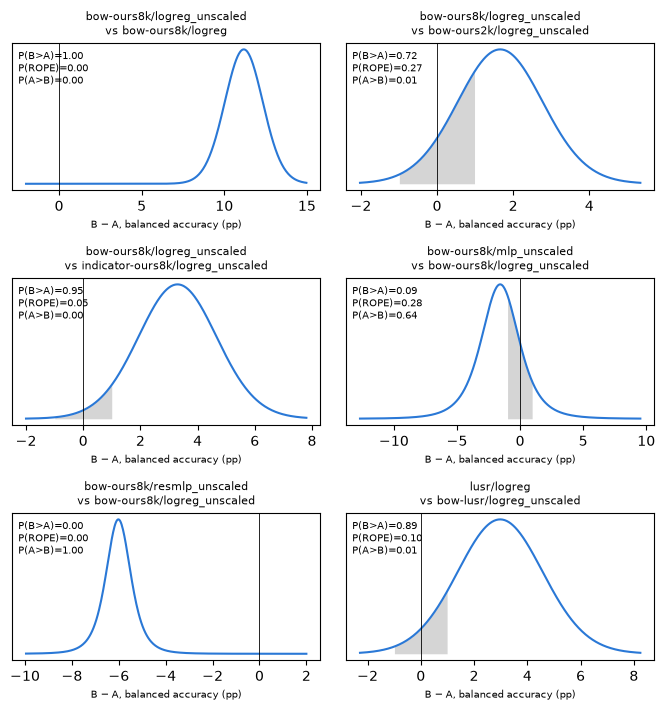

In [16]:
import matplotlib.pyplot as plt

R = H.load_results()
pairs = [
    ("bow-ours8k/logreg", "bow-ours8k/logreg_unscaled"),                  # scaling: +11.2 points
    ("bow-ours2k/logreg_unscaled", "bow-ours8k/logreg_unscaled"),         # tokeniser, unscaled: 2k vs 8k
    ("indicator-ours8k/logreg_unscaled", "bow-ours8k/logreg_unscaled"),   # indicators vs counts, unscaled
    ("bow-ours8k/logreg_unscaled", "bow-ours8k/mlp_unscaled"),            # logreg vs MLP (5 common folds)
    ("bow-ours8k/logreg_unscaled", "bow-ours8k/resmlp_unscaled"),         # logreg vs ResMLP (5 common folds)
    ("bow-lusr/logreg_unscaled", "lusr/logreg"),                          # best token system vs LUSR embeddings
]
table, cmps = A.comparison_table(R, pairs=pairs)
display(table)
A.plot_posteriors(cmps, ncols=2)
plt.show()


**Finding (step 1):** scaling was the main thing holding count features back. When the inner split may choose, it switches scaling off in 50 of 50 folds for bag-of-words and 47 of 50 for indicators. Bag-of-words on 2k rises from 23.9% to **29.7%** (P(better) = 0.999), indicators from 23.4% to 26.3% (P = 0.97). Counts now matter: unscaled bag-of-words beats unscaled indicators by about 3.4 points, whereas with scaling the two were indistinguishable, because scaling inflates rare tokens and drowns out frequency differences in common ones such as punctuation.

The second table shows the MLP has the same handicap: unscaled logistic regression on bag-of-words 2k (30.4%) beats the scaled MLP (25.4%) on the same 5 folds (P = 0.97). Step 2 tests whether that is the model or the input.

**Is the gain only the larger C?** No: in step 1 the scaled options had the same large C values available, and the inner split still never chose them for bag-of-words.

In [17]:
# Step 2. Unscaled variants: same folds, features, grids, early stopping and test as the scaled runs; only the input scaling is left out.
import torch


class UnscaledTorchClassifier(H.TorchClassifier):
    """Same MLP/ResMLP and training as the shared TorchClassifier, but the input is not standardised."""

    def _prep(self, X, fit=False):
        X = X.toarray() if sp.issparse(X) else np.asarray(X)
        return torch.from_numpy(X.astype(np.float32))


H.MODELS["logreg_unscaled"] = H.ModelSpec(
    "logreg_unscaled", lambda p, s: LogisticRegression(C=p["C"], max_iter=3000),
    {"C": [1e-4, 1e-3, 1e-2, 0.1, 1, 10, 100, 1000, 10_000]},  # shared grid extended to large C (section 8)
)
H.MODELS["mlp_unscaled"] = H.ModelSpec(
    "mlp_unscaled", lambda p, s: UnscaledTorchClassifier("mlp", **p), H.MODELS["mlp"].grid, neural=True)
H.MODELS["resmlp_unscaled"] = H.ModelSpec(
    "resmlp_unscaled", lambda p, s: UnscaledTorchClassifier("resmlp", **p), H.MODELS["resmlp"].grid, neural=True)


def cv_unscaled(name, X, model, train=True):
    """Like cv(), without the -sdfix suffix (the scaling fix does not apply when nothing is scaled)."""
    saved = H.load_results(name.replace("/", "__") + ".json")
    if saved and not RECOMPUTE:
        RESULTS[name], status = saved[name], "loaded"
    elif train:
        folds = FOLDS_5 if H.MODELS[model].neural else FOLDS
        RESULTS[name] = H.run_cv(X, y, groups, folds, model, name=name, verbose=False)
        H.save_result(RESULTS[name])
        status = "trained"
    else:
        print(f"{name:38s} not saved yet")
        return None
    ba = H.fold_scores(RESULTS[name])
    print(f"{name:38s} bal.acc {ba.mean():.4f} ± {ba.std():.4f}  ({len(ba)} folds, {status})")
    return RESULTS[name]


TRAIN_UNSCALED = RUN_MISSING  # all runs are saved; set RUN_MISSING = True in the setup cell to retrain missing ones
OURS = ["indicator-ours2k", "bow-ours2k", "indicator-ours4k", "bow-ours4k", "indicator-ours8k", "bow-ours8k"]

for rep in REPS:
    cv_unscaled(f"{rep}/logreg_unscaled", FEATURES[rep], "logreg_unscaled", TRAIN_UNSCALED)  # 50 folds
for m in ["mlp_unscaled", "resmlp_unscaled"]:
    for rep in OURS:  # not run on the LUSR tokeniser and character n-grams (too slow densified, see section 7)
        cv_unscaled(f"{rep}/{m}", FEATURES[rep], m, TRAIN_UNSCALED)  # first 5 folds

RESULTS_ALL.update({k: v for k, v in RESULTS.items() if "unscaled" in k})
RESULTS_ALL.update(H.load_results("lusr-promptcentred__logreg.json"))  # best system overall (neural_project.ipynb / next-steps.md)


indicator-ours2k/logreg_unscaled       bal.acc 0.2642 ± 0.0176  (50 folds, loaded)
bow-ours2k/logreg_unscaled             bal.acc 0.2973 ± 0.0220  (50 folds, loaded)
indicator-ours4k/logreg_unscaled       bal.acc 0.2775 ± 0.0195  (50 folds, loaded)
bow-ours4k/logreg_unscaled             bal.acc 0.3058 ± 0.0176  (50 folds, loaded)
indicator-ours8k/logreg_unscaled       bal.acc 0.2809 ± 0.0201  (50 folds, loaded)
bow-ours8k/logreg_unscaled             bal.acc 0.3138 ± 0.0182  (50 folds, loaded)
indicator-lusr/logreg_unscaled         bal.acc 0.3067 ± 0.0204  (50 folds, loaded)
bow-lusr/logreg_unscaled               bal.acc 0.3281 ± 0.0234  (50 folds, loaded)
char-2-4grams/logreg_unscaled          bal.acc 0.2703 ± 0.0226  (50 folds, loaded)
indicator-ours2k/mlp_unscaled          bal.acc 0.2677 ± 0.0195  (5 folds, loaded)
bow-ours2k/mlp_unscaled                bal.acc 0.2880 ± 0.0082  (5 folds, loaded)
indicator-ours4k/mlp_unscaled          bal.acc 0.2895 ± 0.0220  (5 folds, loaded)
bow-our

In [ ]:
# Extra runs for the model table: MLP and ResMLP on the remaining feature sets, same protocol as above
# (first 5 folds, same grids, early stopping and refit). Results already saved are loaded, not retrained.
#   - LUSR-tokeniser indicators / bag of words and character 2-4-grams: unscaled input, like the other token features
#   - length-only baseline: 6 dense columns (characters, words, sentences and their logs) on very different scales,
#     so it keeps the shared standardised MLP/ResMLP, like the dense embeddings (its logreg row, length/logreg, is scaled too)
# Expected runtime on CPU: about 3.5 hours in total (each sparse set has 16-20k columns, roughly twice the 8k BPE runs).
from shared.data import length_features

TRAIN_EXTRA = True  # False: only load what is saved

for rep in ["indicator-lusr", "bow-lusr", "char-2-4grams"]:
    print(rep, FEATURES[rep].shape)
    for m in ["mlp_unscaled", "resmlp_unscaled"]:
        cv_unscaled(f"{rep}/{m}", FEATURES[rep], m, TRAIN_EXTRA)

X_len = length_features(DATA.train["text"])
cv("length/logreg", X_len, "logreg")  # 50 folds; saved by the embedding notebook, loaded here
if TRAIN_EXTRA:
    RUN_MISSING, _run_missing = True, RUN_MISSING
for m in ["mlp", "resmlp"]:
    cv(f"length/{m}", X_len, m)  # saved as length/mlp-sdfix, length/resmlp-sdfix
if TRAIN_EXTRA:
    RUN_MISSING = _run_missing

RESULTS_ALL.update(RESULTS)


indicator-lusr (2159, 16176)


In [ ]:
# Scaled (shared protocol) vs unscaled, balanced accuracy in % (number of folds)
UNSC_SUMMARY = pd.DataFrame({
    ("logreg", "scaled"): [cell(f"{rep}/logreg") for rep in REPS],
    ("logreg", "unscaled"): [cell(f"{rep}/logreg_unscaled") for rep in REPS],
    ("logreg", "unscaled, first 5"): [cell5(f"{rep}/logreg_unscaled") for rep in REPS],
    ("MLP", "scaled"): [cell(f"{rep}/mlp{NEURAL_SUFFIX}") for rep in REPS],
    ("MLP", "unscaled"): [cell(f"{rep}/mlp_unscaled") for rep in REPS],
    ("ResMLP", "scaled"): [cell(f"{rep}/resmlp{NEURAL_SUFFIX}") for rep in REPS],
    ("ResMLP", "unscaled"): [cell(f"{rep}/resmlp_unscaled") for rep in REPS],
}, index=pd.Index(REPS, name="features"))
display(UNSC_SUMMARY)
print("For reference: LUSR embeddings + logreg", cell("lusr/logreg"), "| prompt-centred LUSR + logreg", cell("lusr-promptcentred/logreg"))


logreg                                    MLP            \
                     scaled   unscaled unscaled, first 5    scaled  unscaled   
features                                                                       
indicator-ours2k  23.4 (50)  26.4 (50)          26.4 (5)  24.2 (5)  26.8 (5)   
bow-ours2k        23.9 (50)  29.7 (50)          30.4 (5)  25.4 (5)  28.8 (5)   
indicator-ours4k  22.8 (50)  27.7 (50)          28.4 (5)  24.2 (5)  28.9 (5)   
bow-ours4k        21.7 (50)  30.6 (50)          31.4 (5)  22.1 (5)  30.3 (5)   
indicator-ours8k  20.7 (50)  28.1 (50)          27.9 (5)  18.4 (5)  28.6 (5)   
bow-ours8k        20.2 (50)  31.4 (50)          32.0 (5)  18.7 (5)  30.4 (5)   
indicator-lusr    20.5 (50)  30.7 (50)          30.4 (5)         –         –   
bow-lusr          20.0 (50)  32.8 (50)          33.2 (5)         –         –   
char-2-4grams     26.0 (50)  27.0 (50)          27.8 (5)         –         –   

                    ResMLP            
                    scaled  unscaled  
features                              
indicator-ours2k  22.9 (5)  22.9 (5)  
bow-ours2k        24.5 (5)  25.2 (5)  
indicator-ours4k  21.8 (5)  24.0 (5)  
bow-ours4k        21.5 (5)  27.4 (5)  
indicator-ours8k  19.3 (5)  24.1 (5)  
bow-ours8k        19.8 (5)  26.0 (5)  
indicator-lusr           –         –  
bow-lusr                 –         –  
char-2-4grams            –         –

For reference: LUSR embeddings + logreg 35.8 (50) | prompt-centred LUSR + logreg 44.1 (50)


The comparisons below use the same Bayesian correlated t-test as section 7 (ROPE = 1 point, verdict when a probability exceeds 0.95). Comparisons with an MLP or ResMLP use their 5 folds.


In [ ]:
U = "logreg_unscaled"
UQ = [("scaling: logreg", f"{rep}/logreg", f"{rep}/{U}") for rep in REPS]
UQ += [(f"scaling: {m}", f"{rep}/{m}{NEURAL_SUFFIX}", f"{rep}/{m}_unscaled") for m in ["mlp", "resmlp"] for rep in OURS]
for f in ["bow", "indicator"]:
    for a, b in [("ours2k", "ours4k"), ("ours4k", "ours8k"), ("ours2k", "ours8k"), ("ours8k", "lusr")]:
        UQ.append(("tokeniser (unscaled)", f"{f}-{a}/{U}", f"{f}-{b}/{U}"))
for tok in ["ours2k", "ours4k", "ours8k", "lusr"]:
    UQ.append(("indicator vs counts (unscaled)", f"indicator-{tok}/{U}", f"bow-{tok}/{U}"))
for rep in OURS:
    UQ += [("architecture (unscaled)", f"{rep}/{U}", f"{rep}/mlp_unscaled"),
           ("architecture (unscaled)", f"{rep}/{U}", f"{rep}/resmlp_unscaled"),
           ("architecture (unscaled)", f"{rep}/mlp_unscaled", f"{rep}/resmlp_unscaled")]
UQ += [("third representation (unscaled)", f"char-2-4grams/{U}", f"bow-lusr/{U}"),
       ("vs LUSR embeddings", f"bow-lusr/{U}", "lusr/logreg"),
       ("vs LUSR embeddings", f"bow-lusr/{U}", "lusr-promptcentred/logreg")]
UQ = [q for q in UQ if have(q[1], q[2])]

UNSC_TABLE, UNSC_CMPS = A.comparison_table(RESULTS_ALL, pairs=[(a, b) for _, a, b in UQ])
UNSC_TABLE.insert(0, "question", [q for q, _, _ in UQ])
UNSC_TABLE["verdict"] = np.select(
    [UNSC_TABLE["P(B>A)"] > 0.95, UNSC_TABLE["P(A>B)"] > 0.95, UNSC_TABLE["P(ROPE)"] > 0.95],
    ["B better", "A better", "practically equivalent"], "undecided")
with pd.option_context("display.max_rows", 100):
    display(UNSC_TABLE)


,question,A,B,folds,mean B−A,P(A>B),P(ROPE),P(B>A),verdict
0,scaling: logreg,indicator-ours2k/logreg,indicator-ours2k/logreg_unscaled,50,0.0307,0.0001,0.0207,0.9792,B better
1,scaling: logreg,bow-ours2k/logreg,bow-ours2k/logreg_unscaled,50,0.0585,0.0000,0.0006,0.9994,B better
2,scaling: logreg,indicator-ours4k/logreg,indicator-ours4k/logreg_unscaled,50,0.0495,0.0000,0.0004,0.9996,B better
3,scaling: logreg,bow-ours4k/logreg,bow-ours4k/logreg_unscaled,50,0.0889,0.0000,0.0000,1.0000,B better
4,scaling: logreg,indicator-ours8k/logreg,indicator-ours8k/logreg_unscaled,50,0.0744,0.0000,0.0000,1.0000,B better
5,scaling: logreg,bow-ours8k/logreg,bow-ours8k/logreg_unscaled,50,0.1118,0.0000,0.0000,1.0000,B better
6,scaling: logreg,indicator-lusr/logreg,indicator-lusr/logreg_unscaled,50,0.1020,0.0000,0.0000,1.0000,B better
7,scaling: logreg,bow-lusr/logreg,bow-lusr/logreg_unscaled,50,0.1285,0.0000,0.0000,1.0000,B better
8,scaling: logreg,char-2-4grams/logreg,char-2-4grams/logreg_unscaled,50,0.0101,0.0456,0.4508,0.5036,undecided
9,scaling: mlp,indicator-ours2k/mlp-sdfix,indicator-ours2k/mlp_unscaled,5,0.0254,0.0323,0.1337,0.8341,undecided


**Findings (step 2):**
- **Standardisation was the main thing holding count features back.** Without it, logistic regression gains 3–13 points on every token feature set, decided in all 8 cases (P ≥ 0.98). The gain grows with the vocabulary: +3–6 on 2k, +5–9 on 4k, +7–11 on 8k, +10–13 on LUSR's tokeniser. That is the predicted mechanism: larger vocabularies have more rare columns, and standardising makes rare columns loud.
- **Character n-grams confirm the mechanism.** They barely change (+1.0, undecided), because the 20,000 most frequent n-grams contain no rare columns (0% occur in fewer than 5 texts, section 4), so standardising has nothing to inflate.
- **The tokeniser ranking reverses.** Unscaled, accuracy rises slightly from 2k (29.7%) to 4k (30.6%), 8k (31.4%) and LUSR's tokeniser (32.8%) for bag-of-words, and similarly for indicators. Every step is undecided (2k vs 8k: +1.7, P = 0.72), so vocabulary size barely matters once the input is not standardised. The 2k advantage in section 7 was a scaling artefact.
- **Counts carry more than indicators.** Unscaled bag-of-words is 2–3 points ahead of indicators for every tokeniser (P = 0.82–0.95), just short of a verdict; under standardisation the two were indistinguishable. How often a token occurs (punctuation, function words) carries signal that scaling hid.
- **The MLPs had the same handicap.** Unscaled, the MLP gains up to 11.7 points (decided for 5 of 6 feature sets) and the ResMLP up to 6.2 (decided for 2).
- **Architectures: the MLP catches up, the ResMLP falls behind.** On the same 5 folds, the unscaled MLP is level with unscaled logistic regression (−1.6 to +0.7, all undecided; practically equivalent on indicators 2k). The unscaled ResMLP is 3–6 points below logistic regression (decided for 2 of 6 feature sets, P(logistic regression better) = 0.85–0.95 for the rest) and below the MLP (decided for 3 of 6). A possible reason, not tested: its LayerNorm layers normalise the hidden activations again, which may bring back part of the effect we removed from the input.
- **Decision:** logistic regression without standardisation. The MLP is no better and costs hours instead of minutes; the ResMLP is worse.
- **The gap to the embeddings mostly closes.** The best token-based system, bag-of-words on LUSR's tokeniser (32.8%), is 3.0 points below LUSR embeddings + logistic regression (35.8%), but that difference is undecided (P = 0.89). Prompt-centred LUSR embeddings (44.1%) stay clearly ahead (+11.2, P = 1.00).

**Why section 7 still uses the shared protocol:** the shared protocol is the same for every representation, and changing it after seeing the results would mix protocol and finding. Section 7 is the comparison under that protocol; this section shows what changes when the one step that hurts count features is removed, with the choice made by the inner split first (step 1).


## 9 · Errors of the best token-based system

best token-based system: bow-lusr/logreg_unscaled


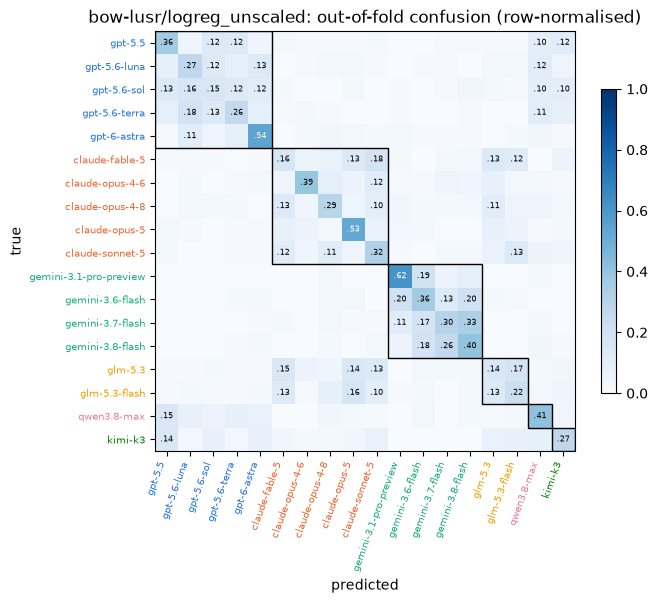

,bow-lusr/logreg_unscaled
model_accuracy,0.332
family_accuracy,0.663
errors,1443.000
within_family_share_of_errors,0.496
within_family_share_if_uniform,0.176


,share of texts
both right,0.191
only bow-lusr/logreg_unscaled right,0.141
only lusr/logreg right,0.176
both wrong,0.492


In [ ]:
TOKEN_SYSTEMS = [n for n in RESULTS_ALL if n.split("/")[0] in FEATURES and n.split("/")[1] in ("logreg", "logreg_scale_tuned", "logreg_unscaled")]
BEST = max(TOKEN_SYSTEMS, key=lambda n: H.fold_scores(RESULTS_ALL[n]).mean())
pred = RESULTS_ALL[BEST]["oof_pred"]  # out-of-fold predictions of the first repeat: one per text
print("best token-based system:", BEST)
A.plot_confusion(y, pred, DATA, title=f"{BEST}: out-of-fold confusion (row-normalised)")
plt.show()
display(A.family_errors(y, pred, DATA).round(3).to_frame(BEST))

lusr_pred = RESULTS_ALL["lusr/logreg"]["oof_pred"]
ok_a, ok_b = pred == y, lusr_pred == y
display(pd.Series({"both right": (ok_a & ok_b).mean(), f"only {BEST} right": (ok_a & ~ok_b).mean(),
                   "only lusr/logreg right": (~ok_a & ok_b).mean(), "both wrong": (~ok_a & ~ok_b).mean()},
                  name="share of texts").round(3).to_frame())

**Reading this:** the confusion matrix is ordered by family, so errors inside a family block are "right family, wrong version". If a noticeable share of texts is right only for the token system, the two make different errors, and combining them (stacking) could beat either one alone.

**Finding:** the two systems make different errors. Only 19% of texts are right for both; 14% are right only for the token system and 18% only for LUSR embeddings. About half of the token system's errors stay inside the right family (50%, against 18% if errors were spread evenly). Combining the two (stacking) is the obvious next step.
